## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"
EXPERIMENT = 'core_identification_paper'

In [2]:
DATA_PATH = f'D:/Google Drive/Work/ITMO/data/{EXPERIMENT}/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/retrained_models/"
RUNS = 25
TOTAL_SPLITS = 1

# Read models

In [3]:
MODELS_DESCRIPTIONS = {


        "core_identification_paper_class2_7": {
        "path": "experiment_results/core_identification_paper/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DRB1*01:01'
                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [7],
        "core_end_state": [8],
        "skip_states": [9, 10, 11, 12],
        "need_to_delete": [111]

    },
                "core_identification_paper_class1_7": {
        "path": "experiment_results/core_identification_paper/",
        "states": 7,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                # 'HLA-DRB1*01:01'
                    'HLA-A*03:01'
                    ],
        "target_lengths": [8, 9, 11, 12],
        "core_start_state": [7],
        "core_end_state": [8],
        "need_to_delete": [111],
        "skip_states": [9],

    },
                        "core_identification_paper_class2_chains": {
        "path": "experiment_results/batched_and_chains/",
        "states": 14,
        "params_string": "1000-min_iters",
        "combination_size": 1,
        "alleles": [
                # 'HLA-DRB1*01:01'
                    'HLA-DPA1*02:02/DPB1*05:01',
                    #'HLA-A*03:01'
                    ],
        "target_lengths": [12, 13,14, 15, 16, 17, 18],
        "core_start_state": [14, 15],
        "core_end_state": [16,17],
        "need_to_delete": [111],
        "skip_states": [],

    },



    

    
    

    



    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [4]:
selected_models = [
     "core_identification_paper_class2_chains"
]
models_to_read = ["v"]

In [5]:
from hmm_logic_methods import load_model

In [6]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_models = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace('/', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    print(bw_model_name)
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_models[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [7]:
per_name_models.keys()

dict_keys(['0_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '1_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '2_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '3_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '4_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '5_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '6_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '7_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '8_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '9_run-12-13-14-15-16-17-18-14-st-viterbi-alg-1000-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0', '10_run-12-13-14-15

## Read data

In [8]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/{EXPERIMENT}/peptide_cores' # work laptop
data_df = pd.read_csv(f"{DATA_PATH}/extractd_cores.csv", index_col=0, sep=';')
USE_WEIGHTS = False


## Show motifs for cores of different lengths

In [9]:
import seaborn as sns
import logomaker
sns.set_theme(style="white")
def make_logo_for_data(binders_array, name, ax=None, mark_left=None, mark_right=None):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
    if mark_left:
        mark_left -= 0.5
        ww_logo.ax.axvline(x=mark_left, color='purple', lw=2)
    if mark_right:
        mark_right -= 0.5
        ww_logo.ax.axvline(x=mark_right, color='purple', lw=2)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [10]:
data_df.peptide_len.value_counts()

14    1241
15    1231
16     927
13     790
17     628
12     420
18     403
Name: peptide_len, dtype: int64

In [11]:
data_df.core_len.value_counts()

9     4327
10    1207
11     103
12       3
Name: core_len, dtype: int64

In [12]:
data_df[data_df.core_len == 9].core_start.value_counts()

4    1308
5    1124
3     625
6     609
2     322
7     211
8      60
1      41
0      15
9      12
Name: core_start, dtype: int64

In [13]:
data_df.core_start.value_counts()

4    1624
5    1459
6     826
3     818
2     426
7     286
8      84
1      71
0      31
9      15
Name: core_start, dtype: int64

In [14]:
data_df[data_df.core_len == 9].peptide_len.value_counts()

14    1031
15     960
13     668
16     660
17     415
12     345
18     248
Name: peptide_len, dtype: int64

In [15]:
target_df = data_df[data_df.peptide_len == 15]

In [29]:
def restricted_motif(df, core_len=None, peptide_len=None, core_start=None, use_peptides=True, peptide_column='peptide', mark_left=None, mark_right=None):
    title_string = ""
    if core_len is not None:
        df = df[df.core_len == core_len]
        title_string = f"{title_string} core len {core_len}"
    if core_start is not None:
        df = df[df.core_start == core_start]
        title_string = f"{title_string} start {core_start}"
    if peptide_len:
        df = df[df.peptide_len == peptide_len]
        title_string = f"{title_string} pep len {peptide_len}"
    peptides = df.index.values
    core_starts = df['core_start'].values
    core_ends = df['core_end'].values
   #cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
    cores= df.core_peptide.values
    make_logo_for_data(cores, f"cores {title_string}")

    if use_peptides:
        peptides_to_draw = df[peptide_column]
        #ensure same size
        len_supossed_to_be = len(peptides_to_draw)
        df = df[df[peptide_column].str.len() == df[peptide_column].str.len().max()]
        peptides_to_draw = df[peptide_column]
        len_that_will_be_used = len(peptides_to_draw)
        if len_supossed_to_be != len_that_will_be_used:
            print(f"found different lengths. Took max. deleted {len_supossed_to_be - len_that_will_be_used} peptides")
        make_logo_for_data(peptides_to_draw, f"Pep {title_string}", mark_left=mark_left, mark_right=mark_right, )
    data_used = df
    return data_used



found different lengths. Took max. deleted 4079 peptides


,allele,simplified_path,core_start_0,core_end_0,core_0,prob_0,core_start_1,core_end_1,core_1,prob_1,...,core_start_24,core_end_24,core_24,prob_24,peptide,core_start,core_end,core_len,peptide_len,core_peptide
EHGLIFMETSAKTASNVE,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 3. 6. 11. 12. 25. 25. 25. 25. 25. 2...,3,13,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. ...,-3.105168,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.944036,...,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.908538,EHGLIFMETSAKTASNVE,6,14,9,18,METSAKTAS
VGVFQHGKVEIIANDQGN,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 0. 0. 0. 5. 24. 24. 25. 25. 2...,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.236611,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.104590,...,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.062369,VGVFQHGKVEIIANDQGN,7,15,9,18,KVEIIANDQ
EDLRSWTAVDTAAQISEQ,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 0. 3. 3. 9. 22. 25. 25. 25. 2...,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.100004,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.085245,...,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.092187,EDLRSWTAVDTAAQISEQ,7,15,9,18,AVDTAAQIS
DSQQLDVFIATSKHAYAT,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 0. 9. 12. 17. 25. 25. 25. 25. 2...,5,14,[0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.844670,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.979650,...,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.004998,DSQQLDVFIATSKHAYAT,4,12,9,18,VFIATSKHA
NLDYERYNSQLLSFVRDL,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 2. 5. 10. 24. 25. 25. 25. 25. 2...,4,12,[0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. ...,-3.123647,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.095099,...,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.066633,NLDYERYNSQLLSFVRDL,6,14,9,18,YNSQLLSFV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
DSDPAAIIHDFEKGMTAY,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 0. 4. 7. 11. 25. 25. 25. 25. 2...,5,13,[0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. ...,-2.958969,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.087194,...,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.061689,DSDPAAIIHDFEKGMTAY,7,15,9,18,IHDFEKGMT
DSDVGEYRAVTELGRPVA,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 0. 1. 4. 19. 19. 25. 25. 25. 2...,5,13,[0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. ...,-3.160171,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.251229,...,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.164262,DSDVGEYRAVTELGRPVA,6,14,9,18,YRAVTELGR
TNEQMHQLVAAYKDAYER,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 1. 4. 6. 11. 25. 25. 25. 25. 2...,5,13,[0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. ...,-3.179556,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.919915,...,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.973060,TNEQMHQLVAAYKDAYER,7,16,9,18,LVAAYKDAY
LSELHPYLHNMKKRDPPS,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 0. 7. 8. 14. 20. 25. 25. 25. 25. 2...,3,12,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. ...,-3.391733,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.302799,...,7,15,[0. 0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. ...,-3.433650,LSELHPYLHNMKKRDPPS,3,13,9,18,PYLHNMKKR


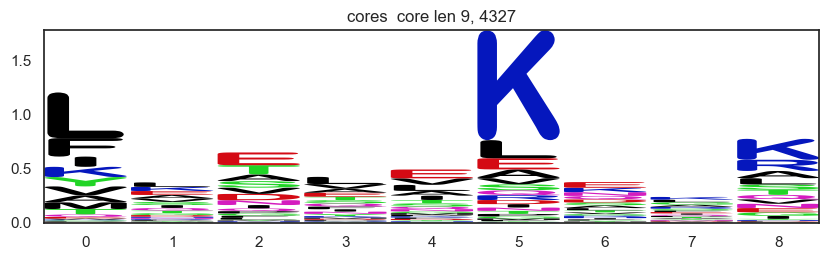

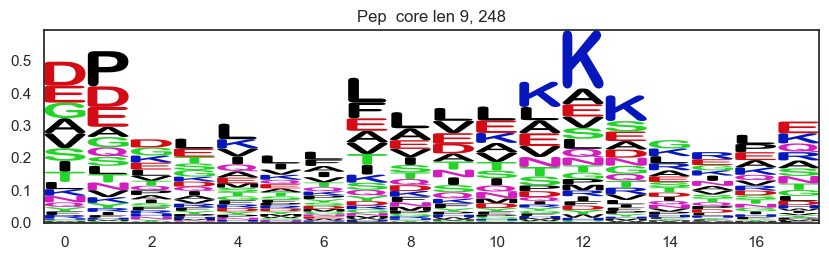

In [30]:
restricted_motif(data_df, core_len=9, use_peptides=True)

In [25]:
data_df[data_df.core_len == 9].core_peptide.str.len().value_counts()

9    4327
Name: core_peptide, dtype: int64

In [ ]:
data_df[data_df.core_len == 9].core_peptide.str.len().value_counts()


In [26]:
data_df[data_df.core_len == 9]

,allele,simplified_path,core_start_0,core_end_0,core_0,prob_0,core_start_1,core_end_1,core_1,prob_1,...,core_start_24,core_end_24,core_24,prob_24,peptide,core_start,core_end,core_len,peptide_len,core_peptide
MPQVPVFTVEVKNYGVK,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 1. 5. 6. 11. 25. 25. 25. 25. 25. 2...,4,12,[0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. ...,-2.961112,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.855575,...,6,14,[0. 0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. ...,-2.868283,MPQVPVFTVEVKNYGVK,6,14,9,17,FTVEVKNYG
RTELETLQKQKK,HLA-DPA1*02:02/DPB1*05:01,[ 0. 4. 8. 25. 25. 25. 25. 25. 25. 25. 23. 18.],1,9,[0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0.],-2.906029,3,11,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.],-2.481375,...,3,11,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.],-2.562591,RTELETLQKQKK,3,11,9,12,LETLQKQKK
IIMDVYSYSEKE,HLA-DPA1*02:02/DPB1*05:01,[ 1. 8. 22. 25. 25. 25. 25. 25. 25. 24. 21. 7.],3,11,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.],-2.885669,2,10,[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-3.495756,...,2,10,[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-3.403041,IIMDVYSYSEKE,2,10,9,12,MDVYSYSEK
QALVEHVKEECD,HLA-DPA1*02:02/DPB1*05:01,[ 4. 11. 25. 25. 25. 25. 25. 25. 25. 22. 14. 2.],0,8,[1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0.],-2.594165,2,10,[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-3.047701,...,2,10,[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-3.132091,QALVEHVKEECD,2,10,9,12,LVEHVKEEC
NHGHILVDYSKNL,HLA-DPA1*02:02/DPB1*05:01,[ 0. 0. 7. 9. 25. 25. 25. 25. 25. 25. 25. 1...,3,11,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-3.079071,4,12,[0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1.],-3.336279,...,2,10,[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0.],-3.265364,NHGHILVDYSKNL,4,12,9,13,ILVDYSKNL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LVEKLGQHLLPWMDR,HLA-DPA1*02:02/DPB1*05:01,[10. 13. 15. 19. 24. 24. 25. 25. 25. 21. 12. 1...,2,10,[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0.],-3.104196,4,12,[0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0.],-3.341526,...,0,9,[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0.],-3.405258,LVEKLGQHLLPWMDR,0,9,9,15,VEKLGQHLL
STPLTIGEKNRNS,HLA-DPA1*02:02/DPB1*05:01,[ 3. 5. 10. 25. 25. 25. 25. 25. 25. 22. 21. 1...,1,9,[0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0.],-3.009119,3,11,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-2.949497,...,3,11,[0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-2.813990,STPLTIGEKNRNS,3,11,9,13,LTIGEKNRN
STKTSAKLSSYT,HLA-DPA1*02:02/DPB1*05:01,[ 6. 23. 24. 25. 25. 25. 25. 25. 25. 22. 2. 1.],1,9,[0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0.],-3.126170,1,9,[0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0.],-3.094947,...,1,9,[0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0.],-2.933739,STKTSAKLSSYT,1,9,9,12,TKTSAKLSS
IASRLGLYSKTSQS,HLA-DPA1*02:02/DPB1*05:01,[ 0. 3. 6. 11. 25. 25. 25. 25. 25. 25. 22. 2...,2,10,[0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0.],-3.067871,4,12,[0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-2.929761,...,4,12,[0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0.],-2.876738,IASRLGLYSKTSQS,4,12,9,14,LGLYSKTSQ


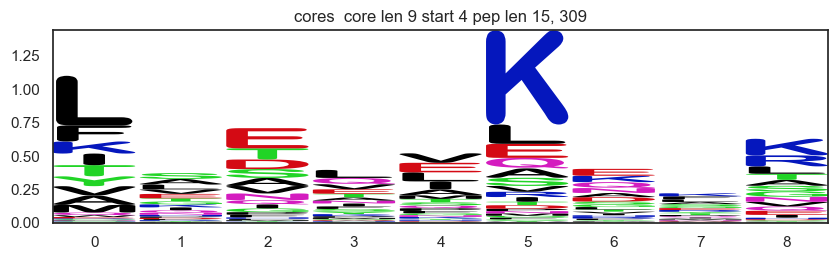

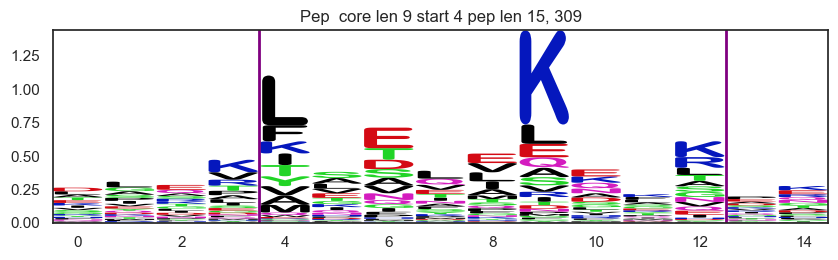

In [35]:
target_peptide_len = 15
target_core_len = 9
core_start = 4
df = restricted_motif(data_df,
                      peptide_len=target_peptide_len, core_len=target_core_len,
                      use_peptides=True,
                      core_start=core_start,mark_left=core_start, mark_right=core_start+target_core_len
                      )


PWM

In [116]:
mixmhc_res = pd.read_csv(f"{DATA_PATH}/cores_mixmhcpred.csv", sep=';')

In [117]:
mixmhc_res

,core
0,LEQLQAVEA
1,MAYVTGGLV
2,FIWVDGSHV
3,YLQMNSLRA
4,VVPMVTQMA
...,...
10327,YAILAARIA
10328,FKLEGALGA
10329,FQMLGSEAA
10330,FAPANALPA


In [122]:
from Bio import motifs

In [123]:
from Bio.Seq import Seq

In [131]:
cores1 = data_df.core_peptide.values
cores2 = mixmhc_res.core.values

In [132]:
len(cores1)

10332

In [133]:
import logomaker
matrix1 = logomaker.alignment_to_matrix(cores1)
matrix2 = logomaker.alignment_to_matrix(cores2)

In [158]:
from Bio.motifs.matrix import PositionWeightMatrix

def distance(v1, v2):
    return np.sqrt(np.sum((v1 - v2) ** 2))   

In [167]:
res_df1 = pd.DataFrame(PositionWeightMatrix(list(matrix.columns.values), matrix1)).T

In [168]:
res_df2 = pd.DataFrame(PositionWeightMatrix(list(matrix.columns.values), matrix2)).T

In [169]:
rand_m = np.random.rand(20,9)

In [170]:
x = res_df1.values
y = res_df2.values
d1 = distance(x, y)

In [171]:
x = rand_m
y = res_df2.values
d2 = distance(x, y)

In [230]:
def make_logo_for_data(binders_array, name, ax=None):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True, ax=ax)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

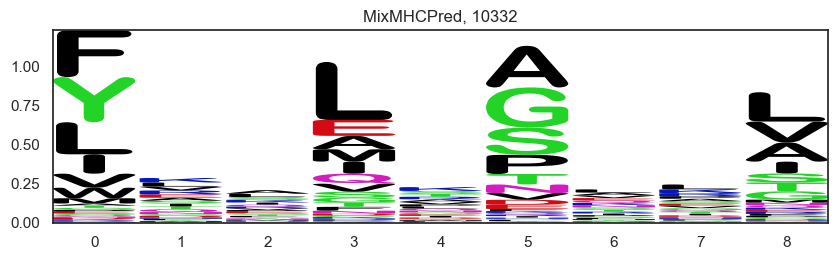

In [165]:
make_logo_for_data(cores2, "MixMHCPred")

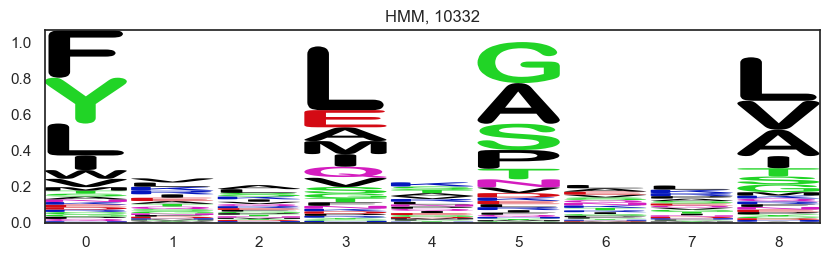

In [166]:
make_logo_for_data(cores1, "HMM")

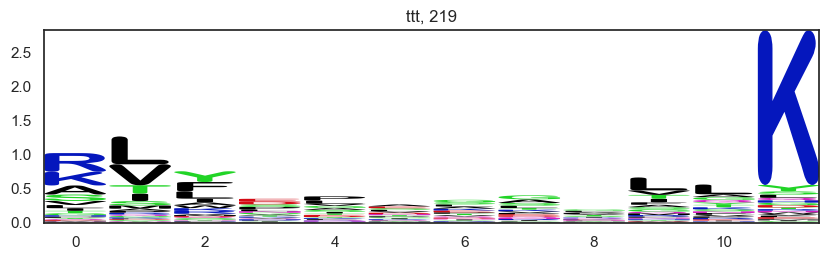

In [231]:
make_logo_for_data(data_df[data_df.peptide_len == 12].peptide, 'ttt')

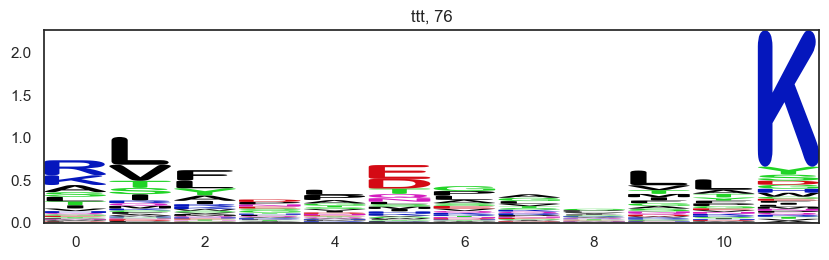

In [232]:
make_logo_for_data(data_df[(data_df.peptide_len == 12) & (data_df.core_len == 11)].peptide, 'ttt')

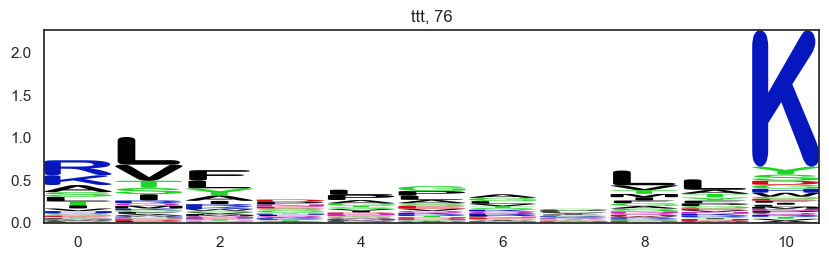

In [234]:
make_logo_for_data(data_df[(data_df.peptide_len == 12) & (data_df.core_len == 11)].core_peptide, 'ttt')

In [178]:
df = {"euclidean distance":[d1, d2], "model":["HMM", "random"]}

In [179]:
df

{'euclidean distance': [0.08913953591435365, 6.985260855639858],
 'model': ['HMM', 'random']}

In [114]:
"""
    A       R       N       D       C       Q       E       G       H       I       L       K       M       F       P       S       T       W       Y       V 
  1 A  -9.831 -10.569 -11.001 -13.023  -7.127 -11.287 -12.476 -11.270  -8.690   1.129   1.503 -11.959   1.348   5.782 -12.669 -11.326  -9.181   4.154   5.433  -0.433 
  2 A  -0.109   1.516   0.851  -3.465  -0.295   1.728  -0.940  -3.101   1.100  -0.711   0.452   1.010   0.908  -0.753  -6.624   0.222   0.159  -2.285   0.397   0.719 
  3 A   1.308   1.659  -0.024  -5.812  -2.549   2.217  -3.278  -0.218   1.748  -0.940   0.152  -0.870   1.788  -1.557  -0.916   0.951   0.336   1.008   0.361  -2.361 
  4 A   0.199  -5.122  -0.779  -5.321  -4.024   0.751  -1.413  -2.897  -2.005   1.663   3.102  -5.252   4.750  -3.297  -2.822  -0.604  -1.192  -6.474  -5.385   0.244 
  5 A   1.581   1.491  -1.260  -3.155  -2.701  -0.297  -0.870  -0.089  -1.512  -1.504   0.496   0.209  -0.655  -1.892   2.425   1.360  -0.293  -3.120  -0.562  -1.275 
  6 A   3.462  -6.210   1.933  -4.515  -8.907  -3.817  -4.582   2.475  -1.802  -4.565  -4.566  -7.595  -3.086  -7.684   3.223   3.603  -0.046  -9.999  -4.323  -4.864 
  7 A   0.789   0.378   0.858  -3.921  -6.442   0.511  -0.470  -2.401   1.227  -0.694   0.112  -1.650   0.926  -0.937   0.703   1.480   0.209  -0.357   1.436   0.487 
  8 A   1.241   2.007  -1.513  -2.903  -1.196  -0.055  -2.334  -1.206  -1.690  -0.847   1.746  -0.601   0.628  -0.347   0.778   1.086  -0.694  -4.292  -0.404  -1.618 
  9 A   1.424  -2.594  -2.227  -7.795  -5.019  -2.999  -6.960  -0.985  -5.655   1.443   2.091  -5.256   1.961  -3.458  -5.514   1.417   1.573  -7.770  -4.481   2.469 
"""
"""
PWM_norm.1	P1	P2	P3	P4	P5	P6	P7	P8	P9
A	0.024	0.9045	2.0092	1.2085	1.0397	4.4356	1.5163	1.0556	2.8332
C	0.0184	0.1107	0.6017	0.2182	0.1326	0.1458	0.1568	0.0932	0.9127
D	0.0077	0.5234	0.3961	0.0757	0.857	0.2376	0.3118	0.6099	0.0606
E	0.0268	1.2289	0.6508	1.6563	0.7286	0.2393	1.3174	0.9314	0.0955
F	8.2876	0.62	1.0232	0.403	0.3905	0.067	0.6291	0.4542	0.0759
G	0.0202	0.4042	0.568	0.3062	0.7221	4.4159	0.4946	0.8855	0.9749
H	0.0131	1.3837	1.6786	0.0713	1.3978	0.0925	1.5118	1.4015	0.1825
I	2.4844	1.4852	1.7607	1.5779	0.7396	0.0165	1.0118	0.7309	1.9882
K	0.0066	1.4779	0.9428	0.0271	1.9151	0.0147	0.9219	1.7297	0.047
L	1.467	0.9127	0.8347	4.4482	0.3557	0.003	0.7652	1.1798	2.4287
M	0.7808	0.5266	1.2065	3.8547	0.9713	0.0059	0.3629	0.6343	0.8621
N	0.0158	1.0459	0.5013	0.2751	1.2904	0.9393	2.4516	0.8159	0.2107
P	0.0197	0.0055	0.7676	0.0114	1.1463	1.7403	0.773	1.615	0.0643
Q	0.035	1.636	1.4102	1.4278	1.4009	0.049	1.8772	1.3262	0.2078
R	0.0144	2.1607	1.0946	0.0132	1.4824	0.0137	0.9713	1.5303	0.0752
S	0.0075	0.6825	1.1882	0.2585	1.1835	1.9537	0.6745	0.6915	0.5976
T	0.0224	0.914	0.491	0.3512	1.7125	0.6946	1.0101	0.6164	1.0159
V	1.0385	1.7998	0.9262	0.5832	0.8786	0.2745	1.376	0.9421	3.7111
W	5.5785	0.6957	0.6203	0.3225	0.0824	0.0202	0.8371	0.224	0.0393
Y	11.2237	0.8956	1.516	0.0241	0.7203	0.0246	0.7936	0.9244	0.0447
"""

'\nPWM_norm.1\tP1\tP2\tP3\tP4\tP5\tP6\tP7\tP8\tP9\nA\t0.024\t0.9045\t2.0092\t1.2085\t1.0397\t4.4356\t1.5163\t1.0556\t2.8332\nC\t0.0184\t0.1107\t0.6017\t0.2182\t0.1326\t0.1458\t0.1568\t0.0932\t0.9127\nD\t0.0077\t0.5234\t0.3961\t0.0757\t0.857\t0.2376\t0.3118\t0.6099\t0.0606\nE\t0.0268\t1.2289\t0.6508\t1.6563\t0.7286\t0.2393\t1.3174\t0.9314\t0.0955\nF\t8.2876\t0.62\t1.0232\t0.403\t0.3905\t0.067\t0.6291\t0.4542\t0.0759\nG\t0.0202\t0.4042\t0.568\t0.3062\t0.7221\t4.4159\t0.4946\t0.8855\t0.9749\nH\t0.0131\t1.3837\t1.6786\t0.0713\t1.3978\t0.0925\t1.5118\t1.4015\t0.1825\nI\t2.4844\t1.4852\t1.7607\t1.5779\t0.7396\t0.0165\t1.0118\t0.7309\t1.9882\nK\t0.0066\t1.4779\t0.9428\t0.0271\t1.9151\t0.0147\t0.9219\t1.7297\t0.047\nL\t1.467\t0.9127\t0.8347\t4.4482\t0.3557\t0.003\t0.7652\t1.1798\t2.4287\nM\t0.7808\t0.5266\t1.2065\t3.8547\t0.9713\t0.0059\t0.3629\t0.6343\t0.8621\nN\t0.0158\t1.0459\t0.5013\t0.2751\t1.2904\t0.9393\t2.4516\t0.8159\t0.2107\nP\t0.0197\t0.0055\t0.7676\t0.0114\t1.1463\t1.7403\t0.773\t1

In [19]:
left_parts = df.peptide.str.slice(0, core_start)
right_parts = df.peptide.str.slice(core_start + target_core_len)


In [20]:
right_parts

SDANTEYERLLSMLN    
APSNEAWASLPAEVL    
TILIKKYNLNRAMML    
VPPADKYKTFEAAFT    
ILRNPGFALLAGFMA    
KDEESYYISEVGAYL    
LVNDRVLDILTANKL    
APGEDRFKPVVPWPH    
FFTTSLFLHLVGFPT    
SETSTEYERLLSMLN    
LHNTSDYYGLVTEQF    
MGQLFSFFEEVPNII    
SPPESSFQKLAPSEY    
FVAGAKYMVIQGEPG    
SGSGGGYGGGSGKSS    
KGSNPNYLALLVKFV    
QKQVQNIRYLVMAIV    
MGQIVTFFQEVPHVI    
DDKETMFIRNCARKV    
VSRTTDFTRLRYLDV    
EPGLCTWQSLRSQIA    
KASNPNYLAILVKYV    
TDGSRGYRLQRNIEN    
LEAVDNWVEFKGYAL    
YPSRKEVKILKGLNL    
RGWKTFYAVLKGTVL    
QRDPEEFKTLIEFHY    
FPPPEEFVFIHAVPV    
LQGPFNFRFLTEKGM    
KLRHSDYEYKVSKLV    
YVGHDEFDAFVAYHI    
FVAAAKYMVIQGEPG    
KGSNPNYLALLVKYV    
HLSIPNFNQYEAMSC    
DKRLAAYLMLMRSPS    
FEQMRLFKTLSSISL    
ATPEAKFDSFVAAFT    
IKCSDHYLCLRCLNV    
IPKEQKYSFLQNPQT    
ESTGGAYDTYKSIPS    
RREVHIYYLEKANKI    
DPDSTDYLILKNLTG    
Name: peptide, dtype: object

In [21]:
matrix = logomaker.alignment_to_matrix(left_parts.values)
matrix_with_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: x[1] == 'P')])
matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: 'P' not in x[0:core_start] )])

# matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: x.contains('P'))])
# matrix = logomaker.alignment_to_matrix(right_parts.values)
# matrix_without_second_p = logomaker.alignment_to_matrix(left_parts[left_parts.apply(lambda x: 'P' not in x and 'G' in x)])


IndexError: string index out of range

In [ ]:
sns.heatmap(matrix, annot=True, linewidth=.5)


<AxesSubplot: ylabel='pos'>

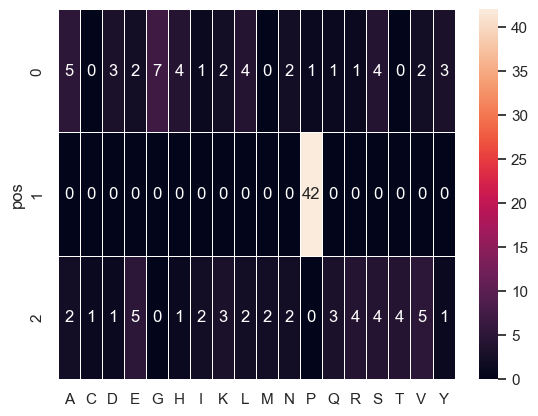

In [38]:
sns.heatmap(matrix_with_second_p, annot=True, linewidth=.5)

<AxesSubplot: ylabel='pos'>

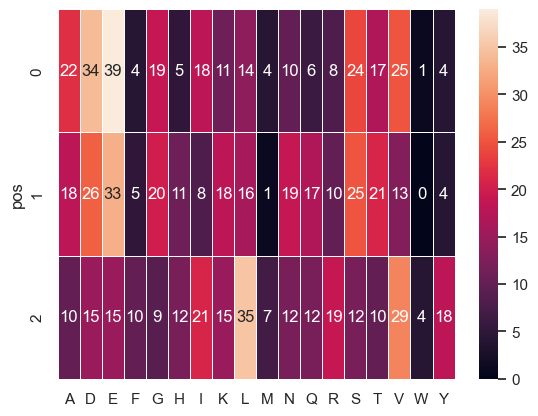

In [39]:
sns.heatmap(matrix_without_second_p, annot=True, linewidth=.5)


In [ ]:
left_parts[left_parts.apply(lambda x: 'P' not in x and 'G' in x)]

## Result if MIXMHCpred


In [18]:
df = pd.read_table('test_data/peptides_mixmhcpred.txt')
df

,Peptide,Context,BestAllele,%Rank_best,Core_best,CoreP1_best,SubSpec_best,%Rank_DPA1_02_01__DPB1_05_01,CoreP1_DPA1_02_01__DPB1_05_01,SubSpec_DPA1_02_01__DPB1_05_01
0,ETSAKEAINVEQAFQTI,NaN,DPA1_02_01__DPB1_05_01,2.070,KEAINVEQA,5,1,2.070,5,1
1,GPESSKKYAEAVTRAKQ,NaN,DPA1_02_01__DPB1_05_01,13.100,KYAEAVTRA,7,1,13.100,7,1
2,THLETFYNEEKDKKF,NaN,DPA1_02_01__DPB1_05_01,0.128,LETFYNEEK,3,-1,0.128,3,-1
3,TSILQTLCEQLRKENEAL,NaN,DPA1_02_01__DPB1_05_01,34.500,LQTLCEQLR,4,-1,34.500,4,-1
4,IPFRAADLLLHSKA,NaN,DPA1_02_01__DPB1_05_01,4.710,RAADLLLHS,4,1,4.710,4,1
...,...,...,...,...,...,...,...,...,...,...
5611,GILDVQSVQEKRKKKE,NaN,DPA1_02_01__DPB1_05_01,8.460,LDVQSVQEK,3,-1,8.460,3,-1
5612,SIIETMKDQQKREIK,NaN,DPA1_02_01__DPB1_05_01,0.699,IETMKDQQK,3,-1,0.699,3,-1
5613,EVLLLKSLGKERKHL,NaN,DPA1_02_01__DPB1_05_01,10.100,VLLLKSLGK,2,-1,10.100,2,-1
5614,LATLETLTKHYGA,NaN,DPA1_02_01__DPB1_05_01,3.390,LATLETLTK,1,-1,3.390,1,-1


In [19]:
df.CoreP1_best.value_counts()

4     1693
3     1475
2      953
5      865
1      339
6      204
7       56
8       17
9       10
10       4
Name: CoreP1_best, dtype: int64

In [20]:
motif_types = list(df.SubSpec_best.value_counts().keys())

NameError: name 'make_logo_for_data' is not defined

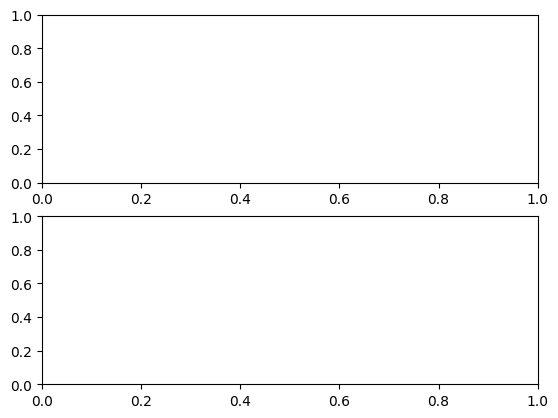

In [21]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(nrows=2)
for i, motif_type in enumerate(motif_types):
    data = df[df.SubSpec_best == motif_type].Core_best.to_numpy()
    make_logo_for_data(data, f"Motif group {motif_type}", ax=axes[i] )
plt.tight_layout()

In [22]:
df = df.rename(columns={"Peptide": "peptide", "CoreP1_best": "core_start", "Core_best":  "core_peptide"  })
df['peptide_len'] = df.peptide.str.len()
df['core_start']  = df['core_start'] - 1
df['core_len'] = df.core_peptide.str.len()
df['core_end'] = df['core_start'] + df['core_len']

df = df.set_index('peptide')
df['peptide'] = df.index.values

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


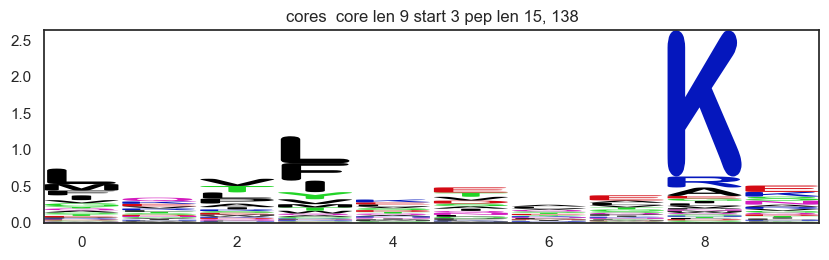

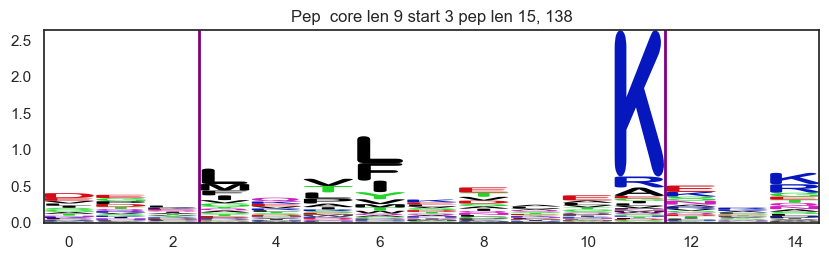

In [110]:
target_peptide_len = 15
target_core_len = 9
core_start = 3
res = restricted_motif(df[df.SubSpec_best == -1],
                      peptide_len=target_peptide_len, core_len=target_core_len,
                      use_peptides=True,
                      core_start=core_start,mark_left=core_start, mark_right=core_start+target_core_len
                      )

In [105]:
df.peptide_len.value_counts()

14    1240
15    1227
16     925
13     789
17     619
12     420
18     396
Name: peptide_len, dtype: int64

In [49]:
    peptides = df.index.values

In [50]:
peptides

array([   0,    1,    2, ..., 5613, 5614, 5615], dtype=int64)

In [73]:
df.core_start.value_counts()

6    17
Name: core_start, dtype: int64

In [17]:
data_df

,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
ETSAKEAINVEQAFQTI,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 4.17 4.17 5.24 5.24 5.24 5.24 ...,ETSAKEAINVEQAFQTI,3,11,9,17,AKEAINVEQ,[4.17 4.17 5.24 5.24 5.24 5.24 5.24 5.24 5.24]
GPESSKKYAEAVTRAKQ,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 0. 4.2 5.22 5.22 5.22 5.22 ...,GPESSKKYAEAVTRAKQ,4,12,9,17,SKKYAEAVT,[4.2 5.22 5.22 5.22 5.22 5.22 5.22 5.22 5.22]
THLETFYNEEKDKKF,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 4.1 5.12 5.12 5.12 5.12 5.12 5.12 ...,THLETFYNEEKDKKF,2,10,9,15,LETFYNEEK,[4.1 5.12 5.12 5.12 5.12 5.12 5.12 5.12 5.12]
TSILQTLCEQLRKENEAL,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 4.13 5.17 5.17 5.17 5.17 5.17 ...,TSILQTLCEQLRKENEAL,3,11,9,18,LQTLCEQLR,[4.13 5.17 5.17 5.17 5.17 5.17 5.17 5.17 5.17]
IPFRAADLLLHSKA,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 2.12 2.12 5.25 5.25 5.25 5.25 5.25 ...,IPFRAADLLLHSKA,4,12,9,14,AADLLLHSK,[5.25 5.25 5.25 5.25 5.25 5.25 5.25 3.13 3.13]
...,...,...,...,...,...,...,...,...,...
GILDVQSVQEKRKKKE,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 4.12 5.14 5.14 5.14 5.14 5.14 5.14 ...,GILDVQSVQEKRKKKE,2,10,9,16,LDVQSVQEK,[4.12 5.14 5.14 5.14 5.14 5.14 5.14 5.14 5.14]
SIIETMKDQQKREIK,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 4.08 5.09 5.09 5.09 5.09 5.09 5.09 ...,SIIETMKDQQKREIK,2,10,9,15,IETMKDQQK,[4.08 5.09 5.09 5.09 5.09 5.09 5.09 5.09 5.09]
EVLLLKSLGKERKHL,HLA-DPA1*02:02/DPB1*05:01,[0. 4.12 5.13 5.13 5.13 5.13 5.13 5.13 5.13 ...,EVLLLKSLGKERKHL,1,9,9,15,VLLLKSLGK,[4.12 5.13 5.13 5.13 5.13 5.13 5.13 5.13 5.13]
LATLETLTKHYGA,HLA-DPA1*02:02/DPB1*05:01,[4.07 5.08 5.08 5.08 5.08 5.08 5.08 5.08 5.08 ...,LATLETLTKHYGA,0,8,9,13,LATLETLTK,[4.07 5.08 5.08 5.08 5.08 5.08 5.08 5.08 5.08]


In [35]:
subset_df = df[df.SubSpec_best == 1] 

In [50]:
peptide = subset_df.iloc[10].peptide

In [51]:
peptide

'SDYNIQKESTLHLVLR'

In [52]:
peptide in data_df.peptide

True

In [56]:
data_df.loc[subset_df.peptide]

,allele,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
ETSAKEAINVEQAFQTI,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 4.17 4.17 5.24 5.24 5.24 5.24 ...,ETSAKEAINVEQAFQTI,3,11,9,17,AKEAINVEQ,[4.17 4.17 5.24 5.24 5.24 5.24 5.24 5.24 5.24]
GPESSKKYAEAVTRAKQ,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 0. 4.2 5.22 5.22 5.22 5.22 ...,GPESSKKYAEAVTRAKQ,4,12,9,17,SKKYAEAVT,[4.2 5.22 5.22 5.22 5.22 5.22 5.22 5.22 5.22]
IPFRAADLLLHSKA,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 2.12 2.12 5.25 5.25 5.25 5.25 5.25 ...,IPFRAADLLLHSKA,4,12,9,14,AADLLLHSK,[5.25 5.25 5.25 5.25 5.25 5.25 5.25 3.13 3.13]
PFRAADLLLHSK,HLA-DPA1*02:02/DPB1*05:01,[0. 4.2 4.2 5.28 5.28 5.28 5.28 5.28 5.28 ...,PFRAADLLLHSK,1,9,9,12,FRAADLLLH,[4.2 4.2 5.28 5.28 5.28 5.28 5.28 5.28 5.28]
VVGKEPESILQVLSQ,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 1.07 1.07 2.13 5.29 5.29 5.29 5.29 ...,VVGKEPESILQVLSQ,5,13,9,15,PESILQVLS,[5.29 5.29 5.29 5.29 5.29 5.29 4.22 4.22 3.16]
...,...,...,...,...,...,...,...,...,...
IMEKTAEHFQEA,HLA-DPA1*02:02/DPB1*05:01,[0. 3.16 5.26 5.26 5.26 5.26 5.26 5.26 5.26 ...,IMEKTAEHFQEA,1,9,9,12,MEKTAEHFQ,[3.16 5.26 5.26 5.26 5.26 5.26 5.26 5.26 5.26]
YRLKEYEKALKYVRG,HLA-DPA1*02:02/DPB1*05:01,[1.06 1.06 5.12 5.12 5.12 5.12 5.12 5.12 5.12 ...,YRLKEYEKALKYVRG,2,10,9,15,LKEYEKALK,[5.12 5.12 5.12 5.12 5.12 5.12 5.12 4.06 4.06]
DLFQKILVPIQQVLKE,HLA-DPA1*02:02/DPB1*05:01,[0. 0. 0. 0. 0. 0. 4.16 5.21 5.21 ...,DLFQKILVPIQQVLKE,6,14,9,16,LVPIQQVLK,[4.16 5.21 5.21 5.21 5.21 5.21 5.21 5.21 5.21]
IKGKTHSQLLIIDR,HLA-DPA1*02:02/DPB1*05:01,[0. 1.1 4.27 5.36 5.36 5.36 5.36 5.36 5.36 ...,IKGKTHSQLLIIDR,2,10,9,14,GKTHSQLLI,[4.27 5.36 5.36 5.36 5.36 5.36 5.36 5.36 4.26]


In [54]:
subset_df.head(50)

,Context,BestAllele,%Rank_best,core_peptide,core_start,SubSpec_best,%Rank_DPA1_02_01__DPB1_05_01,CoreP1_DPA1_02_01__DPB1_05_01,SubSpec_DPA1_02_01__DPB1_05_01,peptide_len,core_len,core_end,peptide
peptide,,,,,,,,,,,,,
ETSAKEAINVEQAFQTI,NaN,DPA1_02_01__DPB1_05_01,2.0700,KEAINVEQA,4,1,2.0700,5,1,17,9,13,ETSAKEAINVEQAFQTI
GPESSKKYAEAVTRAKQ,NaN,DPA1_02_01__DPB1_05_01,13.1000,KYAEAVTRA,6,1,13.1000,7,1,17,9,15,GPESSKKYAEAVTRAKQ
IPFRAADLLLHSKA,NaN,DPA1_02_01__DPB1_05_01,4.7100,RAADLLLHS,3,1,4.7100,4,1,14,9,12,IPFRAADLLLHSKA
PFRAADLLLHSK,NaN,DPA1_02_01__DPB1_05_01,30.4000,RAADLLLHS,2,1,30.4000,3,1,12,9,11,PFRAADLLLHSK
VVGKEPESILQVLSQ,NaN,DPA1_02_01__DPB1_05_01,1.0100,KEPESILQV,3,1,1.0100,4,1,15,9,12,VVGKEPESILQVLSQ
TPGKEAVAMESYAKA,NaN,DPA1_02_01__DPB1_05_01,0.4100,KEAVAMESY,3,1,0.4100,4,1,15,9,12,TPGKEAVAMESYAKA
KTKNSEEFAAAM,NaN,DPA1_02_01__DPB1_05_01,0.1800,KNSEEFAAA,2,1,0.1800,3,1,12,9,11,KTKNSEEFAAAM
EEFKRYEMLKEHER,NaN,DPA1_02_01__DPB1_05_01,1.9400,KRYEMLKEH,3,1,1.9400,4,1,14,9,12,EEFKRYEMLKEHER
HPTKIPVIIERYKG,NaN,DPA1_02_01__DPB1_05_01,2.5100,KIPVIIERY,3,1,2.5100,4,1,14,9,12,HPTKIPVIIERYKG
